 # Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Гнатюк Ярослав'
LIST_NUMBER  = 4

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 4: Одеса, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.1.4


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_одеса


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    t0, b0 = time.time(), cache_bytes()
    g = clean(getter())
    g.to_parquet(path, index=False)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 3)}
    return gpd.read_parquet(path)

In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 163.3 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 28710 | ребер 78272


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [9]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.047,0.687
heritage,знімок,889,0.0,0.253,0.039
stations,знімок,26,0.0,0.036,0.018
amenities,знімок,962,0.0,0.167,0.12
мережа walk,знімок,106982,0.0,5.256,0.25


Живий запит: 5 шарів, передано мережею 14,6 МБ (з них 13,2 МБ — пішохідний
граф), близько 4-5 хв разом із паузами rate limit Overpass. Знімок: 0 МБ мережею,
0,4 с на читання 5,8 МБ GeoParquet. Знімок швидший приблизно в 600 разів; при
повторному запуску не передано 14,6 МБ.

> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
is_hist = heritage['historic'].notna()
is_tour = heritage['tourism'].isin(TOURISM_OK)
mask = is_hist | is_tour
named = heritage['name'].notna()
gone = heritage['disused'].eq('yes') | heritage['moved'].eq('yes')
start = heritage['building'].eq('train_station')

reason = pd.Series(np.select([~named, gone, start],
                             ['немає name', 'демонтовано / перенесено', 'вокзал: старт маршруту'], ''),
                   index=heritage.index)
cand = heritage[mask & reason.eq('')].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', int((mask & named).sum()))
print('з них не демонтовані   :', int((mask & named & ~gone).sum()))
print('з них не вокзал-старт  :', len(cand))

rejected = heritage[mask & reason.ne('')].assign(причина=reason)
rejected['тип'] = ('historic=' + rejected['historic']).fillna('tourism=' + rejected['tourism'])

display(rejected.groupby('причина').agg(**{"об'єктів": ('тип', 'size'),
                                           'з wikidata': ('wikidata', 'count')}))
display(rejected.groupby(['причина', 'тип']).size().rename("об'єктів")
        .sort_values(ascending=False).head(10).to_frame())
display(rejected.loc[rejected['причина'] != 'немає name',
                     ['name', 'historic', 'tourism', 'disused', 'moved', 'wikidata']])

усього у шарі heritage : 889
підходять за тегами    : 889
з них мають name       : 545
з них не демонтовані   : 543
з них не вокзал-старт  : 542


,об'єктів,з wikidata
причина,,
вокзал: старт маршруту,1,1
демонтовано / перенесено,2,1
немає name,344,0


об'єктів
причина                  тип                         
немає name               historic=heritage        161
                         historic=memorial         74
                         tourism=artwork           56
                         tourism=attraction        34
                         tourism=viewpoint          6
                         historic=fort              3
                         historic=yes               3
демонтовано / перенесено historic=memorial          2
немає name               historic=bicycle           2
                         historic=monument          2

,name,historic,tourism,disused,moved,wikidata
7,Пам'ятник засновникам Одеси (демонтований),memorial,None,yes,yes,Q4343543
40,Олександр Суворов (демонтований),memorial,None,yes,None,None
792,Одеський залізничний вокзал,heritage,attraction,None,None,Q2491794


In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial     187
heritage     117
monument      19
cannon         6
synagogue      4
castle         4
yes            4
building       2
aircraft       1
tank           1

=== tourism ===
tourism
artwork       84
attraction    71
museum        42
viewpoint      5
gallery        5

типи геометрії: {'Point': 341, 'Polygon': 196, 'LineString': 5}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [12]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']), metric.area.values, 0.0)

LANG_COLS = cand.columns[cand.columns.str.fullmatch(r'name:[a-z]{2,3}')]

cand['wiki']   = (cand['wikidata'].notna() | cand['wikipedia'].notna()).astype(int)
cand['n_lang'] = cand[LANG_COLS].notna().sum(axis=1)
cand['visit']  = cand['tourism'].isin(['museum', 'gallery']).astype(int)
cand['hist']   = cand['historic'].notna().astype(int)

WEIGHTS = {'wiki': 0.40, 'n_lang': 0.25, 'visit': 0.15, 'hist': 0.10, 'area_m2': 0.10}

def scale(s):
    r = s.rank(pct=True)
    return (r - r.min()) / (r.max() - r.min())

cand['score'] = sum(w * scale(cand[c]) for c, w in WEIGHTS.items())

print('мовні колонки:', ', '.join(LANG_COLS[1:]))
print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мов у назві  :', cand['n_lang'].value_counts().sort_index().to_dict())
print('музей/галерея:', int(cand['visit'].sum()))
print('historic     :', int(cand['hist'].sum()))
print('мають площу  :', int((cand['area_m2'] > 0).sum()))

мовні колонки: name:uk, name:en, name:ar, name:de, name:es, name:ro, name:pl, name:el, name:it, name:be, name:hu, name:ja, name:fr, name:pt
кандидатів   : 542
мають wiki   : 45
мов у назві  : {0: 14, 1: 189, 2: 261, 3: 62, 4: 10, 5: 3, 6: 2, 9: 1}
музей/галерея: 47
historic     : 351
мають площу  : 196


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [13]:
N_SMALL, N_LARGE = 10, 30

def build_tops(cand):
    by_score = cand.nlargest(N_LARGE, 'score')
    by_area = cand.nlargest(N_SMALL, 'area_m2')
    overlap = len(set(by_score.index[:N_SMALL]) & set(by_area.index))
    return (by_score.reset_index(drop=True), by_score.head(N_SMALL).reset_index(drop=True),
            by_area.reset_index(drop=True), overlap)

top_score, top10, top_naive, overlap = build_tops(cand)

score_eq = sum(scale(cand[c]) for c in WEIGHTS) / len(WEIGHTS)
top_eq = cand.loc[score_eq.nlargest(N_SMALL).index]
overlap_eq = len(set(cand.nlargest(N_SMALL, 'score').index) & set(top_eq.index))

print('перетин з рейтингом за площею       : %d з %d' % (overlap, N_SMALL))
print('перетин з рейтингом з рівними вагами: %d з %d' % (overlap_eq, N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                      'за площею': list(top_naive['name']),
                      'рівні ваги': list(top_eq['name'])}))

перетин з рейтингом за площею       : 1 з 10
перетин з рейтингом з рівними вагами: 10 з 10


,за вашим критерієм,за площею,рівні ваги
0,Літературний музей,Свято-успенський патріарший чоловічий монастир...,Потьомкінські сходи
1,Археологічний музей,Ангари,Літературний музей
2,Одеський національний художній музей,Гарматні дворики,Воронцовський палац
3,Потьомкінські сходи,Одеський художній музей,Археологічний музей
4,Воронцовський палац,Одеський академічний театр музичної комедії ім...,Прибутковий будинок Асвадурова
5,Синагога Ор Самеах,Одеський національний академічний театр опери ...,Синагога Ор Самеах
6,Прибутковий будинок Асвадурова,Ангари депо,Одеський національний художній музей
7,Римсько-католицький костьол Успіння Пресвятої ...,Пасаж Менделевичів,Римсько-католицький костьол Успіння Пресвятої ...
8,Шахський палац,Тюремний замок,Шахський палац
9,Одеський художній музей,Головний корпус,Одеський художній музей


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [14]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])


def same_object(a, b):
    return pd.notna(a['wikidata']) and a['wikidata'] == b['wikidata']


def describe_pairs(top):
    rows = []
    for i, j, d in close_pairs(top):
        a, b = top.iloc[i], top.iloc[j]
        rows.append({'A': a['name'], 'B': b['name'], 'відстань, м': round(d),
                     'wikidata A': a['wikidata'], 'wikidata B': b['wikidata'],
                     'рішення': 'дублікат: злити в A' if same_object(a, b)
                                else "різні об'єкти: лишити обидва"})
    return pd.DataFrame(rows)


print('пари ближче 60 м у top_score до чистки:')
display(describe_pairs(top_score))

drop = set()
for i, j, d in close_pairs(cand):
    a, b = cand.iloc[i], cand.iloc[j]
    if same_object(a, b):
        drop.add(cand.index[j] if a['score'] >= b['score'] else cand.index[i])

print('дублікати серед усіх кандидатів (той самий wikidata ближче 60 м), видаляються:')
display(cand.loc[sorted(drop), ['name', 'tourism', 'historic', 'wikidata', 'score']].round(3))

cand = cand.drop(index=sorted(drop))
top_score, top10, top_naive, overlap = build_tops(cand)

print('пари ближче 60 м у top_score після чистки:')
display(describe_pairs(top_score))
print('кандидатів: %d | перетин топ-10 з рейтингом за площею: %d з %d' % (len(cand), overlap, N_SMALL))
display(top10[['name', 'score', 'wiki', 'n_lang', 'visit', 'hist', 'area_m2']].round(3))

пари ближче 60 м у top_score до чистки:


,A,B,"відстань, м",wikidata A,wikidata B,рішення
0,Одеський національний художній музей,Одеський художній музей,21,Q4331480,Q4331480,дублікат: злити в A
1,Будинок О. П. Руссова,Будинок Лібмана,42,Q4165389,Q4165322,різні об'єкти: лишити обидва
2,Літературний музей,Археологічний музей,55,Q4331444,Q7077703,різні об'єкти: лишити обидва


дублікати серед усіх кандидатів (той самий wikidata ближче 60 м), видаляються:


,name,tourism,historic,wikidata,score
4,Потьомкінські сходи,viewpoint,None,Q1413595,0.628
284,ЗіС-3,None,memorial,Q266837,0.547
510,Одеський художній музей,gallery,None,Q4331480,0.802


пари ближче 60 м у top_score після чистки:


,A,B,"відстань, м",wikidata A,wikidata B,рішення
0,Будинок О. П. Руссова,Будинок Лібмана,42,Q4165389,Q4165322,різні об'єкти: лишити обидва
1,Літературний музей,Археологічний музей,55,Q4331444,Q7077703,різні об'єкти: лишити обидва


кандидатів: 539 | перетин топ-10 з рейтингом за площею: 1 з 10


,name,score,wiki,n_lang,visit,hist,area_m2
0,Літературний музей,0.889,1,5,1,0,1382.135
1,Археологічний музей,0.886,1,6,1,0,1015.168
2,Одеський національний художній музей,0.871,1,3,1,0,1607.662
3,Потьомкінські сходи,0.847,1,9,0,1,2824.605
4,Воронцовський палац,0.836,1,4,0,1,1404.100
5,Синагога Ор Самеах,0.832,1,4,0,1,1146.947
6,Прибутковий будинок Асвадурова,0.823,1,3,0,1,1959.270
7,Римсько-католицький костьол Успіння Пресвятої ...,0.820,1,3,0,1,1448.976
8,Шахський палац,0.816,1,3,0,1,1194.503
9,Історико-краєзнавчий музей,0.799,1,2,1,0,2582.411


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [15]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 26
                   name  railway building
0         Одеса-Західна  station     None
1          Одеса-Поїзна  station     None
2       Одеса-Застава 2  station     None
3              Шевченко     halt     None
4     Одеса-Сортувальна  station     None
5                  Депо     halt     None
6         Одеса-Пересип  station     None
7           Житомирська  station     None
8            Одеса-Порт  station     None
9       Одеса-Застава I  station     None
10           Слобідська     halt     None
11  Дальницький Переїзд     halt     None


In [16]:
station = stations[stations['building'].eq('train_station') & stations['name'].notna()]
print('старт:', station['name'].iloc[0])
print('тип:', station.geometry.iloc[0].geom_type)

старт: Одеський залізничний вокзал
тип: Polygon


In [17]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 28710 вузлів, 77397 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [18]:
def check_snap(points, ids, dist, label):
    n_pts, n_nodes = len(ids), len(set(ids))
    far = int(np.argmax(dist))
    print('%s: точок %d, різних вузлів %d' % (label, n_pts, n_nodes))
    print('точка -> вузол: медіана %.1f м, максимум %.1f м (%s)'
          % (np.median(dist), dist[far], points['name'].iloc[far]))
    if n_nodes < n_pts:
        groups = pd.Series(points['name'].values).groupby(ids).agg(list)
        for node, names in groups[groups.map(len) > 1].items():
            print('  злиплись на вузлі %s: %s' % (node, ' | '.join(names)))
    else:
        print('  злиплих точок немає')

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [19]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    ok = np.isfinite(D) & (E > 0) & ~np.eye(len(D), dtype=bool)
    return float(np.median(D[ok] / E[ok]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [20]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

мала задача: точок 11, різних вузлів 10
точка -> вузол: медіана 28.4 м, максимум 40.9 м (Воронцовський палац)
  злиплись на вузлі 4625318489: Літературний музей | Археологічний музей
матриця за 1.309 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.24


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [21]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    tour, left = [0], set(range(1, len(D)))
    while left:
        nxt = min(left, key=lambda j: D[tour[-1], j])
        tour.append(nxt)
        left.remove(nxt)
    return tour + [0]

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best, best_len = list(tour), tour_length(D, tour)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                cand = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                L = tour_length(D, cand)
                if L < best_len - 1e-9:
                    best, best_len, improved = cand, L, True
    return best

In [22]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]

    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]

    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue

            for t in range(N):
                if (S >> t) & 1:
                    continue

                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]

                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j

    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj

    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj

    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [23]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [24]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,10559,25.14
2-opt,8438,0.00
Held-Karp (точний),8438,0.00



оптимальний порядок:
   0. СТАРТ: Одеський залізничний вокзал
   1. Прибутковий будинок Асвадурова
   2. Археологічний музей
   3. Літературний музей
   4. Потьомкінські сходи
   5. Воронцовський палац
   6. Шахський палац
   7. Одеський національний художній музей
   8. Історико-краєзнавчий музей
   9. Римсько-католицький костьол Успіння Пресвятої Богородиці Діви Марії
  10. Синагога Ор Самеах
  11. СТАРТ: Одеський залізничний вокзал

довжина: 8.44 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [25]:
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = 2 ** (n - 1) * (n - 1)
    rows.append({'точок n': n, 'клітин': f'{cells:,}', 'ГБ (8 байт/клітина)': round(cells * 8 / 1e9, 4)})
display(pd.DataFrame(rows).set_index('точок n'))

,клітин,ГБ (8 байт/клітина)
точок n,,
11,"10,240",0.0001
16,"491,520",0.0039
21,"20,971,520",0.1678
26,"838,860,800",6.7109
31,"32,212,254,720",257.6980


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [26]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

велика задача: точок 31, різних вузлів 30
точка -> вузол: медіана 22.7 м, максимум 46.6 м (Свято-Успенський кафедральний собор УПЦ МП)
  злиплись на вузлі 4625318489: Літературний музей | Археологічний музей
коефіцієнт обходу: 1.27
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    27468 м
2-opt            :    23092 м  за 0.025 с  (коротше на 15.9%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
кандидатів 539 у 219 комірках
половина кандидатів — у 35 комірках (16% зайнятих)
максимум в одній комірці: 24
30 точок маршруту займають 22 комірок


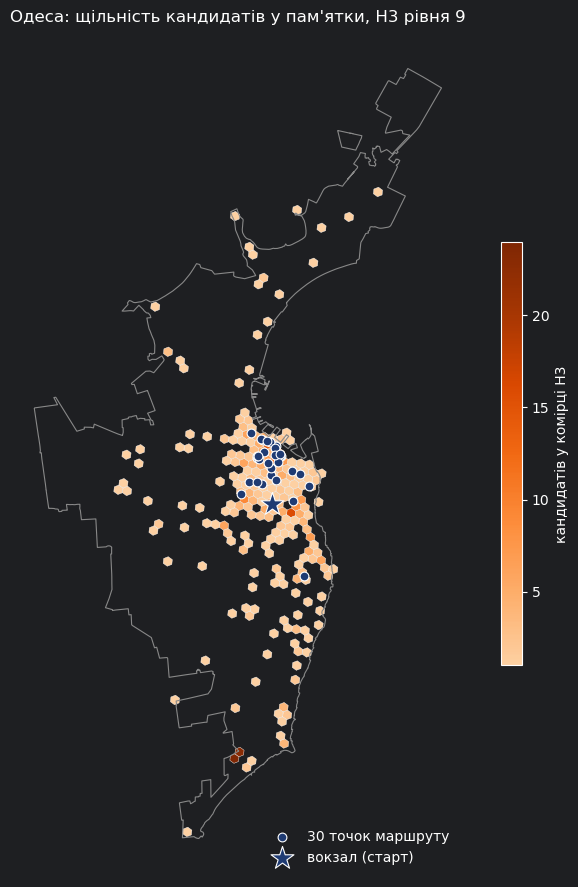

In [27]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in cand.geometry.representative_point()]
dens = cand['h3'].value_counts().rename_axis('h3').reset_index(name='n')
hexes = gpd.GeoDataFrame(
    dens,
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in dens['h3']],
    crs='EPSG:4326')

half = int((dens['n'].cumsum() < dens['n'].sum() / 2).sum()) + 1
route_cells = {h3.latlng_to_cell(p.y, p.x, H3_RES) for p in pts30.geometry[1:]}
print('кандидатів %d у %d комірках' % (len(cand), len(dens)))
print('половина кандидатів — у %d комірках (%.0f%% зайнятих)' % (half, 100 * half / len(dens)))
print('максимум в одній комірці: %d' % dens['n'].max())
print('30 точок маршруту займають %d комірок' % len(route_cells))

ORANGES = plt.matplotlib.colors.ListedColormap(plt.cm.Oranges(np.linspace(0.25, 1, 256)))

fig, ax = plt.subplots(figsize=(10, 11))
hexes.plot(ax=ax, column='n', cmap=ORANGES, edgecolor='white', linewidth=0.3, legend=True,
           legend_kwds={'label': 'кандидатів у комірці H3', 'shrink': 0.5})
boundary.boundary.plot(ax=ax, color='#888888', linewidth=0.8)
pts30.iloc[1:].plot(ax=ax, color='#1f3b73', edgecolor='white', linewidth=0.8, markersize=40,
                    label='30 точок маршруту')
pts30.iloc[:1].plot(ax=ax, color='#1f3b73', edgecolor='white', linewidth=0.8, marker='*',
                    markersize=300, label='вокзал (старт)')
ax.legend(loc='lower right', frameon=False)
ax.set_title("Одеса: щільність кандидатів у пам'ятки, H3 рівня %d" % H3_RES)
ax.set_axis_off()
plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [28]:
route10 = pts10.iloc[ex10[:-1]].reset_index(drop=True).to_crs(32635)
amen_m = amenities[['amenity', 'name', 'geometry']].to_crs(32635)
print('закладів у шарі:', amen_m['amenity'].value_counts().to_dict())

near = gpd.sjoin_nearest(route10, amen_m, how='left', distance_col='відстань_м')
near = near[~near.index.duplicated()]
display(pd.DataFrame({'точка маршруту': near['name_left'],
                      'найближчий заклад': near['amenity'],
                      'назва': near['name_right'],
                      'відстань, м': near['відстань_м'].round(0)}))

by_type = pd.DataFrame({'точка маршруту': route10['name']})
for kind in ['cafe', 'restaurant', 'drinking_water', 'toilets']:
    j = gpd.sjoin_nearest(route10, amen_m[amen_m['amenity'] == kind], distance_col='d')
    by_type[kind + ', м'] = j[~j.index.duplicated()]['d'].round(0)
display(by_type)
print('медіана до найближчого закладу: %.0f м' % near['відстань_м'].median())

закладів у шарі: {'cafe': 556, 'restaurant': 275, 'toilets': 113, 'drinking_water': 18}


,точка маршруту,найближчий заклад,назва,"відстань, м"
0,СТАРТ: Одеський залізничний вокзал,cafe,None,14.0
1,Прибутковий будинок Асвадурова,cafe,Дядя Миша,97.0
2,Археологічний музей,cafe,Omega Three,61.0
3,Літературний музей,cafe,Omega Three,106.0
4,Потьомкінські сходи,toilets,None,58.0
5,Воронцовський палац,toilets,None,47.0
6,Шахський палац,toilets,None,119.0
7,Одеський національний художній музей,toilets,None,23.0
8,Історико-краєзнавчий музей,cafe,Базилик,33.0
9,Римсько-католицький костьол Успіння Пресвятої ...,restaurant,Хаджибей,49.0


,точка маршруту,"cafe, м","restaurant, м","drinking_water, м","toilets, м"
0,СТАРТ: Одеський залізничний вокзал,14.0,528.0,974.0,74.0
1,Прибутковий будинок Асвадурова,97.0,149.0,573.0,644.0
2,Археологічний музей,61.0,126.0,274.0,113.0
3,Літературний музей,106.0,136.0,298.0,115.0
4,Потьомкінські сходи,117.0,137.0,145.0,58.0
5,Воронцовський палац,272.0,270.0,431.0,47.0
6,Шахський палац,159.0,198.0,696.0,119.0
7,Одеський національний художній музей,348.0,376.0,927.0,23.0
8,Історико-краєзнавчий музей,33.0,44.0,567.0,59.0
9,Римсько-католицький костьол Успіння Пресвятої ...,108.0,49.0,663.0,153.0


медіана до найближчого закладу: 49 м


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [29]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

road_line = route_coords(ex10, ids10)
straight_line = [(p.y, p.x) for p in pts10.geometry.iloc[ex10]]
L_road, L_straight = tour_length(D10, ex10), tour_length(E10, ex10)
print('по ребрах графа : %.2f км' % (L_road / 1000))
print('прямі відрізки  : %.2f км' % (L_straight / 1000))
print('різниця         : %.2f км (дорога довша в %.2f раза)' % ((L_road - L_straight) / 1000, L_road / L_straight))

fmap = folium.Map(tiles=BASEMAP)
road = folium.FeatureGroup(name='маршрут по ребрах графа, %.2f км' % (L_road / 1000)).add_to(fmap)
straight = folium.FeatureGroup(name='прямі відрізки, %.2f км' % (L_straight / 1000)).add_to(fmap)
folium.PolyLine(road_line, color='#1f3b73', weight=4, opacity=0.85).add_to(road)
folium.PolyLine(straight_line, color='#d9480f', weight=2, dash_array='6 6').add_to(straight)

for step, i in enumerate(ex10[:-1]):
    p = pts10.geometry.iloc[i]
    label = 'S' if step == 0 else str(step)
    folium.Marker(
        [p.y, p.x], tooltip='%s. %s' % (label, pts10['name'].iloc[i]),
        icon=folium.DivIcon(icon_size=(24, 24), icon_anchor=(12, 12), html=(
            '<div style="width:24px;height:24px;border-radius:12px;background:#1f3b73;'
            'border:2px solid white;color:white;font:bold 12px sans-serif;'
            'display:flex;align-items:center;justify-content:center">%s</div>' % label))
    ).add_to(fmap)

folium.LayerControl(collapsed=False).add_to(fmap)
fmap.fit_bounds([[min(c[0] for c in road_line), min(c[1] for c in road_line)],
                 [max(c[0] for c in road_line), max(c[1] for c in road_line)]])
fmap.save('lr5_маршрут.html')
print('збережено lr5_маршрут.html (%.0f КБ)' % (os.path.getsize('lr5_маршрут.html') / 1024))
fmap

по ребрах графа : 8.44 км
прямі відрізки  : 6.80 км
різниця         : 1.64 км (дорога довша в 1.24 раза)
збережено lr5_маршрут.html (24 КБ)


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [30]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (17.7 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [32]:
REPORT = '''
1. Відкинуто 347 з 889: 344 без name, 2 демонтовані, 1 вокзал. За тегами не відкинуто нічого. Без пояснень фільтр не віддав би: 161 пам'ятка архітектури втрачена лише через відсутність назви.

2. Ваги: wiki 0.40, мови name:xx 0.25, museum/gallery 0.15, historic 0.10, площа 0.10, кожен сигнал через rank(pct=True). Wiki єдиний зовнішній сигнал, тому найважчий; площа найслабша, бо великими бувають склади й ангари.

3. За площею збігся 1 з 10, з рівними вагами 10 з 10. "Найкращі" це рішення аналітика, а не властивість даних.

4. Коефіцієнт обходу 1,24 (10 об'єктів) і 1,27 (30): типовий, збігається з теорією для прямокутної сітки (4/π = 1,27). Недосяжних пар немає, асиметрія 0 м.

5. Найближчий сусід 10 559 м проти оптимуму 8 438 м: гірший на 25,1%. 2-opt на 11 точках знайшов оптимум; на 30 точках він коротший за найближчого сусіда на 15,9% (23 092 проти 27 468 м).

6. Таблиця Held-Karp для 31 точки має 2^30 * 30 = 32,2 млрд клітин, тобто 258 ГБ при 8 байтах на клітину: не вміщається в пам'ять.

7. Проблеми з даними: дублікати з однаковим wikidata (Потьомкінські сходи, художній музей, гармати ЗіС-3) злито, лишено запис з вищим балом; демонтовані пам'ятники відкинуто; вокзал виключено з цілей; Літературний і Археологічний музеї сіли на один вузол (0 м замість ~55 м), похибка менша за 1%; питної води лише 18 точок на місто.


Декларація про використання ШІ:
Використовувався Claude : код усіх завдань і пояснення. Перевірка: самоперевірки ноутбука (check_tour, assert-и для 2-opt і
Held-Karp), контрольні ознаки з завдання (Point і Polygon серед кандидатів, коефіцієнт обходу в межах 1,2-1,6, знімок з 0 МБ при повторному запуску), ручна перевірка проміжних даних (демонтовані пам'ятники, пари-дублікати, злиплі точки), візуальна перевірка H3-картограми і карти маршруту.
'''
print(REPORT)


1. Відкинуто 347 з 889: 344 без name, 2 демонтовані, 1 вокзал. За тегами не відкинуто нічого. Без пояснень фільтр не віддав би: 161 пам'ятка архітектури втрачена лише через відсутність назви.

2. Ваги: wiki 0.40, мови name:xx 0.25, museum/gallery 0.15, historic 0.10, площа 0.10, кожен сигнал через rank(pct=True). Wiki єдиний зовнішній сигнал, тому найважчий; площа найслабша, бо великими бувають склади й ангари.

3. За площею збігся 1 з 10, з рівними вагами 10 з 10. "Найкращі" це рішення аналітика, а не властивість даних.

4. Коефіцієнт обходу 1,24 (10 об'єктів) і 1,27 (30): типовий, збігається з теорією для прямокутної сітки (4/π = 1,27). Недосяжних пар немає, асиметрія 0 м.

5. Найближчий сусід 10 559 м проти оптимуму 8 438 м: гірший на 25,1%. 2-opt на 11 точках знайшов оптимум; на 30 точках він коротший за найближчого сусіда на 15,9% (23 092 проти 27 468 м).

6. Таблиця Held-Karp для 31 точки має 2^30 * 30 = 32,2 млрд клітин, тобто 258 ГБ при 8 байтах на клітину: не вміщається в пам